# Cell Tracking — TemporalUNet3D + SimpleNodeTransformer

Mirrors the structure of `nnUNet.ipynb` but for the tracking task.

Pipeline:
1. **Data** — zarr images + geff tracks
2. **Dataset** — `TrackDataset`: sliding windows of W consecutive frames
3. **Model** — `UNetNodeTransformer`: UNet features + detection head + cross-attention edge predictor
4. **Inference** — load checkpoint, detect peaks, show results

In [45]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [46]:
cd ../src

/data/kaggle-cell-tracking/src


In [47]:
import glob
import json
import torch
import zarr
import polars as pl
import numpy as np
import tracksdata as td
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

from pathlib import Path
from collections import Counter

In [48]:
from tracking.dataset import TrackDataset
from tracking.data import load_dataset_windows

from tracking.targets import detect_and_match, build_matched_edge_targets, pos_embed_torch
from tracking.losses import TrackingLoss, detection_loss, edge_loss
from tracking.post_process import detect_peaks
from tracking.plot import plot_detection, plot_edges, plot_sample

from model_zoo.models_track import define_track_model, UNetNodeTransformer
from tracking_cellmot.io import open_dataset, list_datasets


In [49]:
from params import TRAIN_DIR, LOG_FOLDER, SCALE

TRAIN_DIR = Path(TRAIN_DIR)
LOG_FOLDER = Path(LOG_FOLDER)

DOWNSAMPLE = (1, 1, 1)   # (Z, Y, X) strides used at training time
WINDOW_SIZE = 2

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {device}")

Device: cuda


## 1. Data

Each sample is a pair of files:
- `.zarr` — 4D image volume `(T, Z, Y, X)` uint16
- `.geff` — cell tracks (node coordinates + edges between consecutive frames)

In [50]:
all_paths = list_datasets(TRAIN_DIR, require_geff=True)

embryos = [p.name.split('_')[0] for p in all_paths]
Counter(embryos)

Counter({'6bba': 128, '44b6': 71})

## 2. Dataset — what gets fed to the model

`TrackDataset` produces fixed-size windows of `W` consecutive frames:
- `imgs`: `(W, Z_ds, Y_ds, X_ds)` float16 — normalised, spatially downsampled
- `coords`: `(W, max_nodes, 3)` — GT node positions in downsampled space
- `masks`: `(W, max_nodes)` bool — which slots are real nodes
- `targets`: `(W-1, max_nodes, max_nodes)` — GT transition matrices

In [51]:
ds_path = all_paths[0]
ds_path.name

'44b6_0113de3b'

In [52]:
vm, windows = load_dataset_windows(
    ds_path, window_size=WINDOW_SIZE,
)

print(vm)

VideoMeta(zarr_path=PosixPath('../input/train/44b6_0113de3b.zarr'), image_shape=(100, 64, 256, 256), voxel_size=(1.625, 0.40625, 0.40625), q_low=26.222222222222225, q_high=2145.000000039654)


In [53]:
win_idx = max(range(len(windows)), key=lambda i: sum(windows[i].node_counts))  # max frames number
w = windows[win_idx]

print(windows[win_idx])

FrameWindowData(t_start=0, n_frames=2, coords=[tensor([[ 63., 222., 249.]]), tensor([[ 63., 227., 251.]])], node_counts=[1, 1], targets=[tensor([[1.]])])


In [54]:
ds = TrackDataset(
    [(vm, windows)],
    augment=False,
    crop_size=(64, 128, 128)
)

In [55]:
%%time

sample = ds[win_idx]

print("\nSample keys/shapes:")
for k, v in sample.items():
    if isinstance(v, torch.Tensor):
        print(f"  {k:12s}  {tuple(v.shape)}  {v.dtype}")


Sample keys/shapes:
  coords        (2, 1, 3)  torch.float32
  masks         (2, 1)  torch.bool
  targets       (1, 1, 1)  torch.float32
  node_counts   (2,)  torch.int64
  imgs          (2, 64, 256, 256)  torch.float16
  image_shape   (4,)  torch.int64
  voxel_size    (3,)  torch.float32
CPU times: user 735 ms, sys: 298 ms, total: 1.03 s
Wall time: 81.4 ms


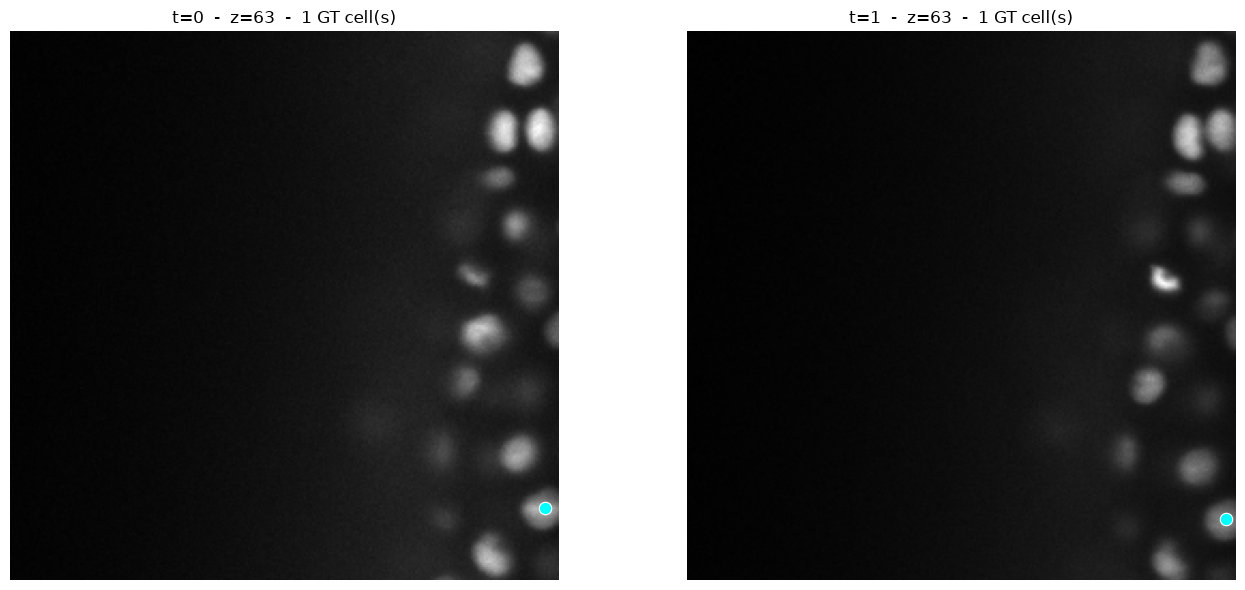

In [56]:
sample = ds[win_idx]

plot_sample(sample, t_start=windows[win_idx].t_start)

Detection target shape: (64, 256, 256)
Positive voxels: 2 / 4194304


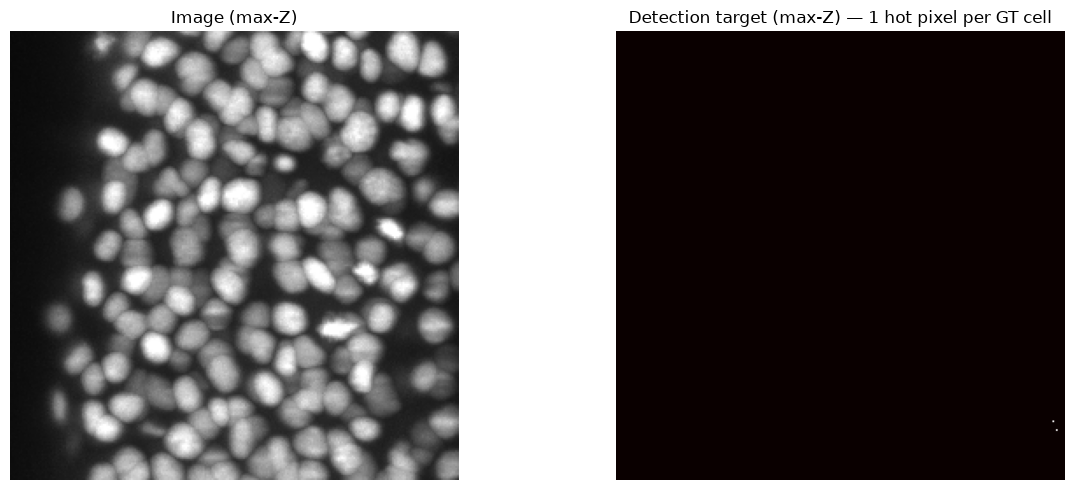

In [57]:
# Detection target: binary mask at GT node voxels (what the detection head is trained to predict)
from tracking.targets import build_detection_target

det_target = build_detection_target(
    sample["coords"], sample["masks"], sample["image_shape"][1:].tolist()
)
det_target_np = det_target.amax(0).numpy()

print(f"Detection target shape: {det_target_np.shape}")
print(f"Positive voxels: {int(det_target_np.sum())} / {det_target_np.size}")

# Max-Z projection
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].imshow(sample["imgs"][0].amax(0).numpy(), cmap="gray", vmin=0, vmax=1)
axes[0].set_title("Image (max-Z)")
axes[0].axis("off")
axes[1].imshow(det_target_np.max(0), cmap="hot", vmin=0, vmax=1)
axes[1].set_title("Detection target (max-Z) — 1 hot pixel per GT cell")
axes[1].axis("off")
plt.tight_layout()
plt.show()

In [58]:
# # GT transition matrix — visualise which cells link across frames
# target_matrix = sample["targets"][0].numpy()   # (max_nodes, max_nodes)
# masks = sample["masks"].numpy()

# n0_real = int(masks[0].sum())
# n1_real = int(masks[1].sum())
# mat_crop = target_matrix[:n0_real, :n1_real]

# fig, ax = plt.subplots(figsize=(max(4, n1_real + 1), max(4, n0_real + 1)))
# im = ax.imshow(mat_crop, cmap="Blues", vmin=0, vmax=1, aspect="auto")
# ax.set_xlabel(f"Target cells at t={windows[win_idx].t_start + 1}")
# ax.set_ylabel(f"Source cells at t={windows[win_idx].t_start}")
# ax.set_title("GT transition matrix  (1 = linked)")
# ax.set_xticks(range(n1_real))
# ax.set_yticks(range(n0_real))
# plt.colorbar(im, ax=ax, shrink=0.6)
# plt.tight_layout()
# plt.show()
# print("Matrix:")
# print(mat_crop)

## 3. Model

`UNetNodeTransformer` = `TemporalUNet3D` + detection head + `SimpleNodeTransformer`

1. **encode(imgs)** → UNet features `(B, W, C, Z_ds, Y_ds, X_ds)` + detection logits `(B, 1, Z_ds, Y_ds, X_ds)` per frame
2. **detect_and_match** → detected peak coords + sinusoidal pos-embeddings
3. **_index_features** → UNet features at detected positions
4. **predict_edges** → cross-attention transformer → `(B, N_src, N_tgt)` edge logits

In [59]:
from model_zoo.models_track import define_track_model

In [60]:
model = define_track_model(
    unet_out_channels=32,
    unet_layers=[32, 64, 128],
    transformer_hidden=128,
    transformer_heads=4,
    transformer_blocks=4,
    unet_pool_stride=(1, 2, 2),
    unet_n_decode_steps=0,
    verbose=1
).to(device)

In [129]:
weights = torch.load("/data/kaggle-cell-tracking/logs/2026-08-13/25/fold_0/ckpt_08000.pt")
# weights = torch.load("/data/kaggle-cell-tracking/logs/2026-08-13/7/fold_0/ckpt_final.pt")
model.load_state_dict(weights['model_state_dict'])


<All keys matched successfully>

In [130]:
print(f"Total parameters : {model.count_parameters() / 1e6:.2f}M")
print(f"  UNet           : {sum(p.numel() for p in model.unet.parameters()) / 1e6:.2f}M")
print(f"  Detect head    : {sum(p.numel() for p in model.detect_head.parameters()) / 1e6:.2f}M")
print(f"  Transformer    : {sum(p.numel() for p in model.transformer.parameters()) / 1e6:.2f}M")

Total parameters : 1.53M
  UNet           : 0.95M
  Detect head    : 0.00M
  Transformer    : 0.58M


In [131]:
sample = ds[win_idx]
imgs_batch = sample["imgs"].float().unsqueeze(0).to(device)

bs, window_size, d, h, w = imgs_batch.shape
print('Input shape:', imgs_batch.shape)

coords = sample["coords"].to(device).unsqueeze(0)
masks = sample["masks"].to(device).unsqueeze(0)
targets = sample["targets"].to(device).unsqueeze(0)

image_shape = tuple(sample["image_shape"].tolist())
voxel_size = tuple(sample["voxel_size"].tolist())

image_shape, voxel_size

Input shape: torch.Size([1, 2, 64, 256, 256])


((100, 64, 256, 256), (1.625, 0.40625, 0.40625))

In [132]:
unet_out, det_logits = model.encode(imgs_batch)

UNetNodeTransformer - Encode - Input shape: torch.Size([1, 2, 64, 256, 256])
TemporalUNet3D - Encoder Block 0 - Input shape: torch.Size([2, 1, 64, 256, 256])
TemporalUNet3D - Encoder Block 1 - Input shape: torch.Size([2, 32, 64, 256, 256])
TemporalUNet3D - Encoder Block 2 - Input shape: torch.Size([2, 64, 64, 128, 128])
TemporalUNet3D - Encoder output shape: torch.Size([2, 128, 64, 64, 64])
UNetNodeTransformer - Encode - UNet output shape: torch.Size([1, 2, 32, 64, 64, 64])
UNetNodeTransformer - Encode - Detect logits shape: [torch.Size([1, 1, 64, 64, 64]), torch.Size([1, 1, 64, 64, 64])]


In [133]:
bs, window_size, d, h, w = imgs_batch.shape
d_out, h_out, w_out = unet_out.shape[-3:]

unet_scaling = (d // d_out, h // h_out, w // w_out)

print(unet_scaling)
print(voxel_size)

(1, 4, 4)
(1.625, 0.40625, 0.40625)


In [134]:
det_probas = imgs_batch[:, :, ::unet_scaling[0], ::unet_scaling[1], ::unet_scaling[2]]
det_probas.size()

torch.Size([1, 2, 64, 64, 64])

In [138]:
det_coords[:, 337], coords[:, i, :] / torch.tensor(unet_scaling).to(det_coords)

(tensor([[60., 63., 62.]], device='cuda:0'),
 tensor([[[63.0000, 56.7500, 62.7500]]], device='cuda:0'))

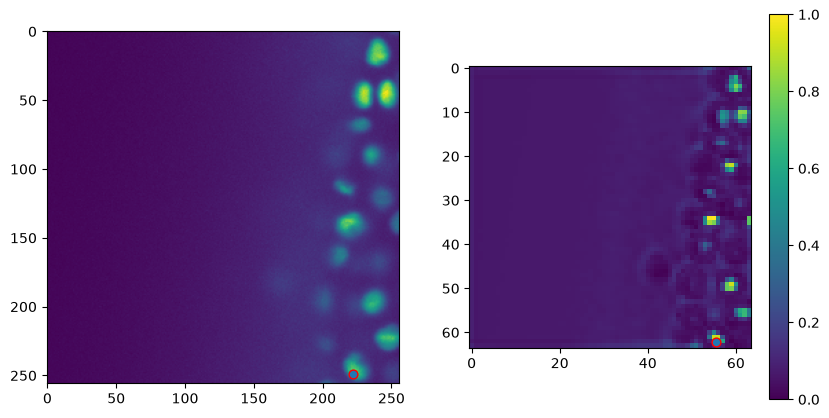

Pred peaks size: torch.Size([1, 113, 3])
Peak matches with gt tensor([[ 63., 222., 249.]], device='cuda:0'): tensor([62., 55., 61.], device='cuda:0')


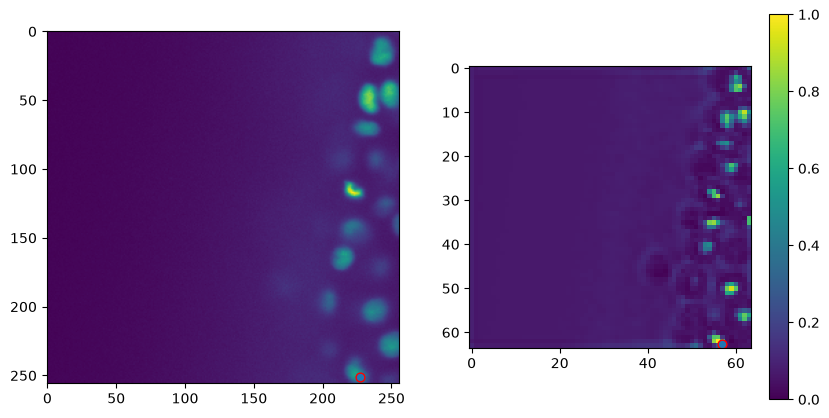

Pred peaks size: torch.Size([1, 141, 3])
Peak matches with gt tensor([[ 63., 227., 251.]], device='cuda:0'): tensor([62., 56., 62.], device='cuda:0')


In [174]:
frame_det = []

frame = 63

with torch.no_grad():
    det_probas = [det.sigmoid() for det in det_logits]
    for i in range(WINDOW_SIZE):         

        plt.figure(figsize=(10, 5))
        plt.subplot(1, 2, 1)
        plt.imshow(sample["imgs"][i].squeeze()[frame].cpu().numpy())
        plt.scatter(
            coords[:, i, :, 1].cpu().numpy(),
            coords[:, i, :, 2].cpu().numpy(),
            c=None,
            edgecolor="r",
            marker="o",
            s=40,
        )
        plt.subplot(1, 2, 2)
        plt.imshow(det_probas[i].squeeze()[frame].cpu().numpy())
        plt.scatter(
            coords[:, i, :, 1].cpu().numpy() / unet_scaling[1],
            coords[:, i, :, 2].cpu().numpy() / unet_scaling[2],
            c=None,
            edgecolor="r",
            marker="o",
            s=40,
        )
        plt.colorbar()
        plt.show()

        det_coords, det_pos_embed, det_mask, matches = detect_and_match(
            det_probas[i],
            coords[:, i],
            masks[:, i],
            image_shape,
            voxel_size=voxel_size,
            unet_scaling=unet_scaling,
            pool_kernel_um=5,
            frame_index=i,
            window_size=WINDOW_SIZE,
            det_threshold=0.5
        )
        unet_feat = model._index_features(
            unet_out[:, i], det_coords, det_mask,
        )
        frame_det.append((det_coords, det_pos_embed, det_mask, matches, unet_feat))

        print("Pred peaks size:", det_coords.size())
        # print("Pred mask:", det_mask)
        if matches[0].max() > -1:
            print(f"Peak matches with gt {coords[:, i][int(matches[0].max())]}: {det_coords[0][int(matches[0].argmax())]}")
        else:
            print("No matches")

        # break

In [175]:
edge_logits_list = []
edge_targets_list = []
det_mask_pairs = []

for i in range(WINDOW_SIZE - 1):
    ns = frame_det[i][0].shape[1]  # number of source nodes
    nt = frame_det[i + 1][0].shape[1]  # number of target nodes

    pair_target = build_matched_edge_targets(
        frame_det[i][3],  # matches at frame i
        frame_det[i + 1][3],  # matches at frame i+1
        targets[:, i],  # gt transition matrix at frame i
        ns,  # number of source nodes
        nt,  # number of target nodes
    )  # which node pairs are linked

    # Forward of the edge scorer - score each node pair
    edge_log = model.predict_edges(
        unet_feat_src=frame_det[i][4],  # frame i UNet features
        unet_feat_tgt=frame_det[i + 1][4],  # frame i+1 UNet features
        coords_src=frame_det[i][0],  # frame i coords
        coords_tgt=frame_det[i + 1][0],  # frame i+1 coords
        pos_feat_src=frame_det[i][1],  # frame i pos-embed
        pos_feat_tgt=frame_det[i + 1][1],  # frame i+1 pos-embed
        mask_src=frame_det[i][2],  # frame i mask
        mask_tgt=frame_det[i + 1][2],  # frame i+1 mask
    )
    edge_logits_list.append(edge_log)
    edge_targets_list.append(pair_target)
    det_mask_pairs.append((frame_det[i][2], frame_det[i + 1][2]))

### Loss

In [176]:
from tracking.losses import TrackingLoss

In [177]:
criterion = TrackingLoss(**{
        "det_loss_weight": 1.0,
        "det_neg_weight": 0.1,
        "det_weak_weight": 0.3,        # weight for image-derived weak positives
        "det_weak_smoothing": 0.1,     # smoothing factor for weak positives
    }
)

In [178]:
%%time
loss, breakdown = criterion(
    det_logits,
    [coords[:, i] for i in range(window_size)],
    [masks[:, i] for i in range(window_size)],
    edge_logits_list,
    edge_targets_list,
    det_mask_pairs,
    imgs_per_frame=[imgs_batch[:, i] for i in range(window_size)],
    unet_scaling=unet_scaling,
)

CPU times: user 9.09 ms, sys: 4.33 ms, total: 13.4 ms
Wall time: 13 ms


In [179]:
breakdown

{'det': 0.03288458287715912,
 'edge': 0.018690625205636024,
 'total': 0.051575206220149994}

Done !